# Recovery: GWB (13/3, -14) + band noise LOFAR (-12.3)

Dati da `Simulations_GWB_A140_bn_A123_sv44.ipynb`: rumore standard (alpha = 4.4) + GWB (gamma = 13/3, log10_A = -14)
+ band noise LOFAR (gamma = 3, log10_A = -12.3, 50 componenti). Nessuno dei due e nel modello a 6 par; il modello
a 8 par aggiunge il band noise (il GWB resta non modellato in entrambi).

Confronti (modello a 6 par, catene gia esistenti):

| | catena | notebook |
|---|---|---|
| dati reali DR2low, alpha = 4.4 | `test_real_sv44/` | 10 |
| sim senza GWB e senza band (OFF) | `test_sim_bn_OFF_50comp/` | 21 |
| sim con GWB (-14) e senza band | `test_gwb_A140_g433_sv44/` | 12 (**sampling ancora da lanciare**) |
| sim senza GWB, con band a -12.5 | `test_sim_bn_A125_50comp/` | 21 |

Attenzione: le simulazioni di confronto hanno un modello di iniezione diverso (meno processi), quindi una
realizzazione diversa di red noise, DM e scattering anche con lo stesso seed. Le differenze fra le posteriori
includono anche il rumore di realizzazione; il band noise di confronto e a -12.5, non a -12.3.

In [1]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import re
from PTMCMCSampler.PTMCMCSampler import PTSampler as ptmcmc
from scipy.stats import uniform
import jax

import time
import emcee
import corner

Optional mpi4py package is not installed.  MPI support is not available.


In [2]:
##### Cell for the prior distributions ###################################################################################

my_priordict = {}
my_priordict["(.*_)?sv_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?sv_gp_alpha.*"] = [0, 10]
my_priordict["(.*_)?sv_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_log10_A.*"] = [-10, 1]
my_priordict["(.*_)?sw_gamma.*"] = [-5, 6]
my_priordict["(.*_)?dm_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?dm_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?red_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?red_noise_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_n_earth.*"] = [0, 30]
# band noise: stesse prior degli altri processi power-law
my_priordict["(.*_)?band_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?band_noise_log10_A.*"] = [-20, -11]


def build_priors(param_names, priordict):
    """
    Build a {param_name: scipy dist} dict with uniform prior distributions in the range
    """
    priors = {}
    unmatched = []
    for name in param_names:
        matched = False
        for pattern, (lo, hi) in priordict.items():
            if re.fullmatch(pattern, name):
                priors[name] = uniform(loc=lo, scale=hi - lo)
                matched = True
                break
        if not matched:
            unmatched.append(name)

    if unmatched:
        print(f"Warning: no prior found for {len(unmatched)} parameters, "
              f"falling back to standard normal:\n  {unmatched}")
    return priors

## Dati simulati: GWB a -14 + band noise a -12.3

In [3]:
gwbbn_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A123_GWB_A140_sv44_50componenti/J1640+2224')   # GWB a -14 + band noise a -12.3
print('nome     :', gwbbn_psr.name)
print('N_TOA    :', len(gwbbn_psr.toas))
print('shape M  :', gwbbn_psr.Mmat.shape)

nome     : J1640+2224
N_TOA    : 6777
shape M  : (6777, 39)


## Modello a 6 par (senza band noise, senza GWB)

In [4]:
# modello a 6 par: quello standard, senza band noise
model_gwbbn_6par = [gwbbn_psr.residuals]
model_gwbbn_6par += [ds.makegp_timing(gwbbn_psr, svd=True)]
model_gwbbn_6par += [ds.makenoise_measurement(gwbbn_psr, gwbbn_psr.noisedict, tnequad=True, ecorr=True)]
model_gwbbn_6par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_red_components'],
                                 T=ds.getspan(gwbbn_psr), name='red_noise'))
model_gwbbn_6par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_dm_components'],
                                 T=ds.getspan(gwbbn_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_gwbbn_6par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_chrom_components'],
                                 T=ds.getspan(gwbbn_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_gwbbn_6par = ds.PulsarLikelihood(model_gwbbn_6par).logL
logL_gwbbn_6par.params

['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [5]:
def params_dict_from_array_gwbbn_6par(x):
    x = np.asarray(x)
    return dict(zip(logL_gwbbn_6par.params, x))

priors_gwbbn_6par = build_priors(logL_gwbbn_6par.params, my_priordict)

def log_prior_gwbbn_6par(x):
    params = params_dict_from_array_gwbbn_6par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_gwbbn_6par:
            logp += priors_gwbbn_6par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_gwbbn_6par():
    return np.array([priors_gwbbn_6par[name].rvs() for name in logL_gwbbn_6par.params])

x0_gwbbn_6par = prior_draw_gwbbn_6par()

In [6]:
@jax.jit
def _jit_logL_gwbbn_6par(params_array):
    return logL_gwbbn_6par(dict(zip(logL_gwbbn_6par.params, params_array)))

def log_likelihood_gwbbn_6par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_gwbbn_6par(jnp.array(x))))

print('logL iniziale =', log_likelihood_gwbbn_6par(x0_gwbbn_6par))

logL iniziale = 67601.728434212


In [7]:
sampler_gwbbn_6par = ptmcmc(
    ndim=len(logL_gwbbn_6par.params),
    logl=log_likelihood_gwbbn_6par,
    logp=log_prior_gwbbn_6par,
    cov=np.eye(len(logL_gwbbn_6par.params)) * 0.001,
    outDir='./test_sim_bn_A123_GWB_6par/',
    resume=True
)

In [8]:
ESEGUI_SAMPLING_GWBBN_6PAR = True   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_GWBBN_6PAR:
    print("Starting sampling (GWB -14 + band noise -12.3, modello a 6 par)...")
    sampler_gwbbn_6par.sample(x0_gwbbn_6par, Niter=1000000, thin=10)

Starting sampling (GWB -14 + band noise -12.3, modello a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 21.408998 s Acceptance rate = 0.2158Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 2182.140412 s Acceptance rate = 0.379595
Run Complete


In [9]:
chain_gwbbn_6par = np.loadtxt('./test_sim_bn_A123_GWB_6par/chain_1.txt')[:, :-4]
chain_gwbbn_6par = chain_gwbbn_6par[len(chain_gwbbn_6par)//4:]
chain_gwbbn_6par.shape

(75001, 6)

In [10]:
tau_gwbbn_6par = emcee.autocorr.integrated_time(chain_gwbbn_6par, has_walkers=False, quiet=True)
print('tau:', tau_gwbbn_6par)
print('Effective length =', int(len(chain_gwbbn_6par) / tau_gwbbn_6par.max()))

tau: [4.0786137  3.81647795 4.50042301 3.55029626 3.91086725 3.2487424 ]
Effective length = 16665


## Modello a 8 par (con band noise, senza GWB)

In [11]:
# modello a 8 par: i 6 standard + band noise sui backend LOFAR
model_gwbbn_8par = [gwbbn_psr.residuals]
model_gwbbn_8par += [ds.makegp_timing(gwbbn_psr, svd=True)]
model_gwbbn_8par += [ds.makenoise_measurement(gwbbn_psr, gwbbn_psr.noisedict, tnequad=True, ecorr=True)]
model_gwbbn_8par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_red_components'],
                                 T=ds.getspan(gwbbn_psr), name='red_noise'))
model_gwbbn_8par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_dm_components'],
                                 T=ds.getspan(gwbbn_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_gwbbn_8par.append(ds.makegp_fourier(gwbbn_psr, ds.powerlaw, gwbbn_psr.noisedict[gwbbn_psr.name + '_chrom_components'],
                                 T=ds.getspan(gwbbn_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
model_gwbbn_8par.append(ds.makegp_fourier_select(gwbbn_psr, ds.powerlaw, components=50, T=ds.getspan(gwbbn_psr),
                                        name='band_noise', selection=ds.lofar_backends))

logL_gwbbn_8par = ds.PulsarLikelihood(model_gwbbn_8par).logL
logL_gwbbn_8par.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [12]:
def params_dict_from_array_gwbbn_8par(x):
    x = np.asarray(x)
    return dict(zip(logL_gwbbn_8par.params, x))

priors_gwbbn_8par = build_priors(logL_gwbbn_8par.params, my_priordict)

def log_prior_gwbbn_8par(x):
    params = params_dict_from_array_gwbbn_8par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_gwbbn_8par:
            logp += priors_gwbbn_8par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_gwbbn_8par():
    return np.array([priors_gwbbn_8par[name].rvs() for name in logL_gwbbn_8par.params])

x0_gwbbn_8par = prior_draw_gwbbn_8par()

In [13]:
@jax.jit
def _jit_logL_gwbbn_8par(params_array):
    return logL_gwbbn_8par(dict(zip(logL_gwbbn_8par.params, params_array)))

def log_likelihood_gwbbn_8par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_gwbbn_8par(jnp.array(x))))

print('logL iniziale =', log_likelihood_gwbbn_8par(x0_gwbbn_8par))

logL iniziale = 67228.5563702776


In [14]:
sampler_gwbbn_8par = ptmcmc(
    ndim=len(logL_gwbbn_8par.params),
    logl=log_likelihood_gwbbn_8par,
    logp=log_prior_gwbbn_8par,
    cov=np.eye(len(logL_gwbbn_8par.params)) * 0.001,
    outDir='./test_sim_bn_A123_GWB_8par/',
    resume=True
)

In [17]:
ESEGUI_SAMPLING_GWBBN_8PAR = True   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_GWBBN_8PAR:
    print("Starting sampling (GWB -14 + band noise -12.3, modello a 8 par)...")
    sampler_gwbbn_8par.sample(x0_gwbbn_8par, Niter=1000000, thin=10)

Starting sampling (GWB -14 + band noise -12.3, modello a 8 par)...
Finished 1.00 percent (1.00 percent of new work) in 34.467386 s Acceptance rate = 0.2279Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 2481.982587 s Acceptance rate = 0.305782
Run Complete


In [18]:
chain_gwbbn_8par = np.loadtxt('./test_sim_bn_A123_GWB_8par/chain_1.txt')[:, :-4]
chain_gwbbn_8par = chain_gwbbn_8par[len(chain_gwbbn_8par)//4:]
chain_gwbbn_8par.shape

(75001, 8)

In [19]:
tau_gwbbn_8par = emcee.autocorr.integrated_time(chain_gwbbn_8par, has_walkers=False, quiet=True)
print('tau:', tau_gwbbn_8par)
print('Effective length =', int(len(chain_gwbbn_8par) / tau_gwbbn_8par.max()))

tau: [6.17697735 6.25831327 6.61038555 5.8295316  5.48448205 3.27406663
 7.26865699 5.10232262]
Effective length = 10318


## Corner delle due run

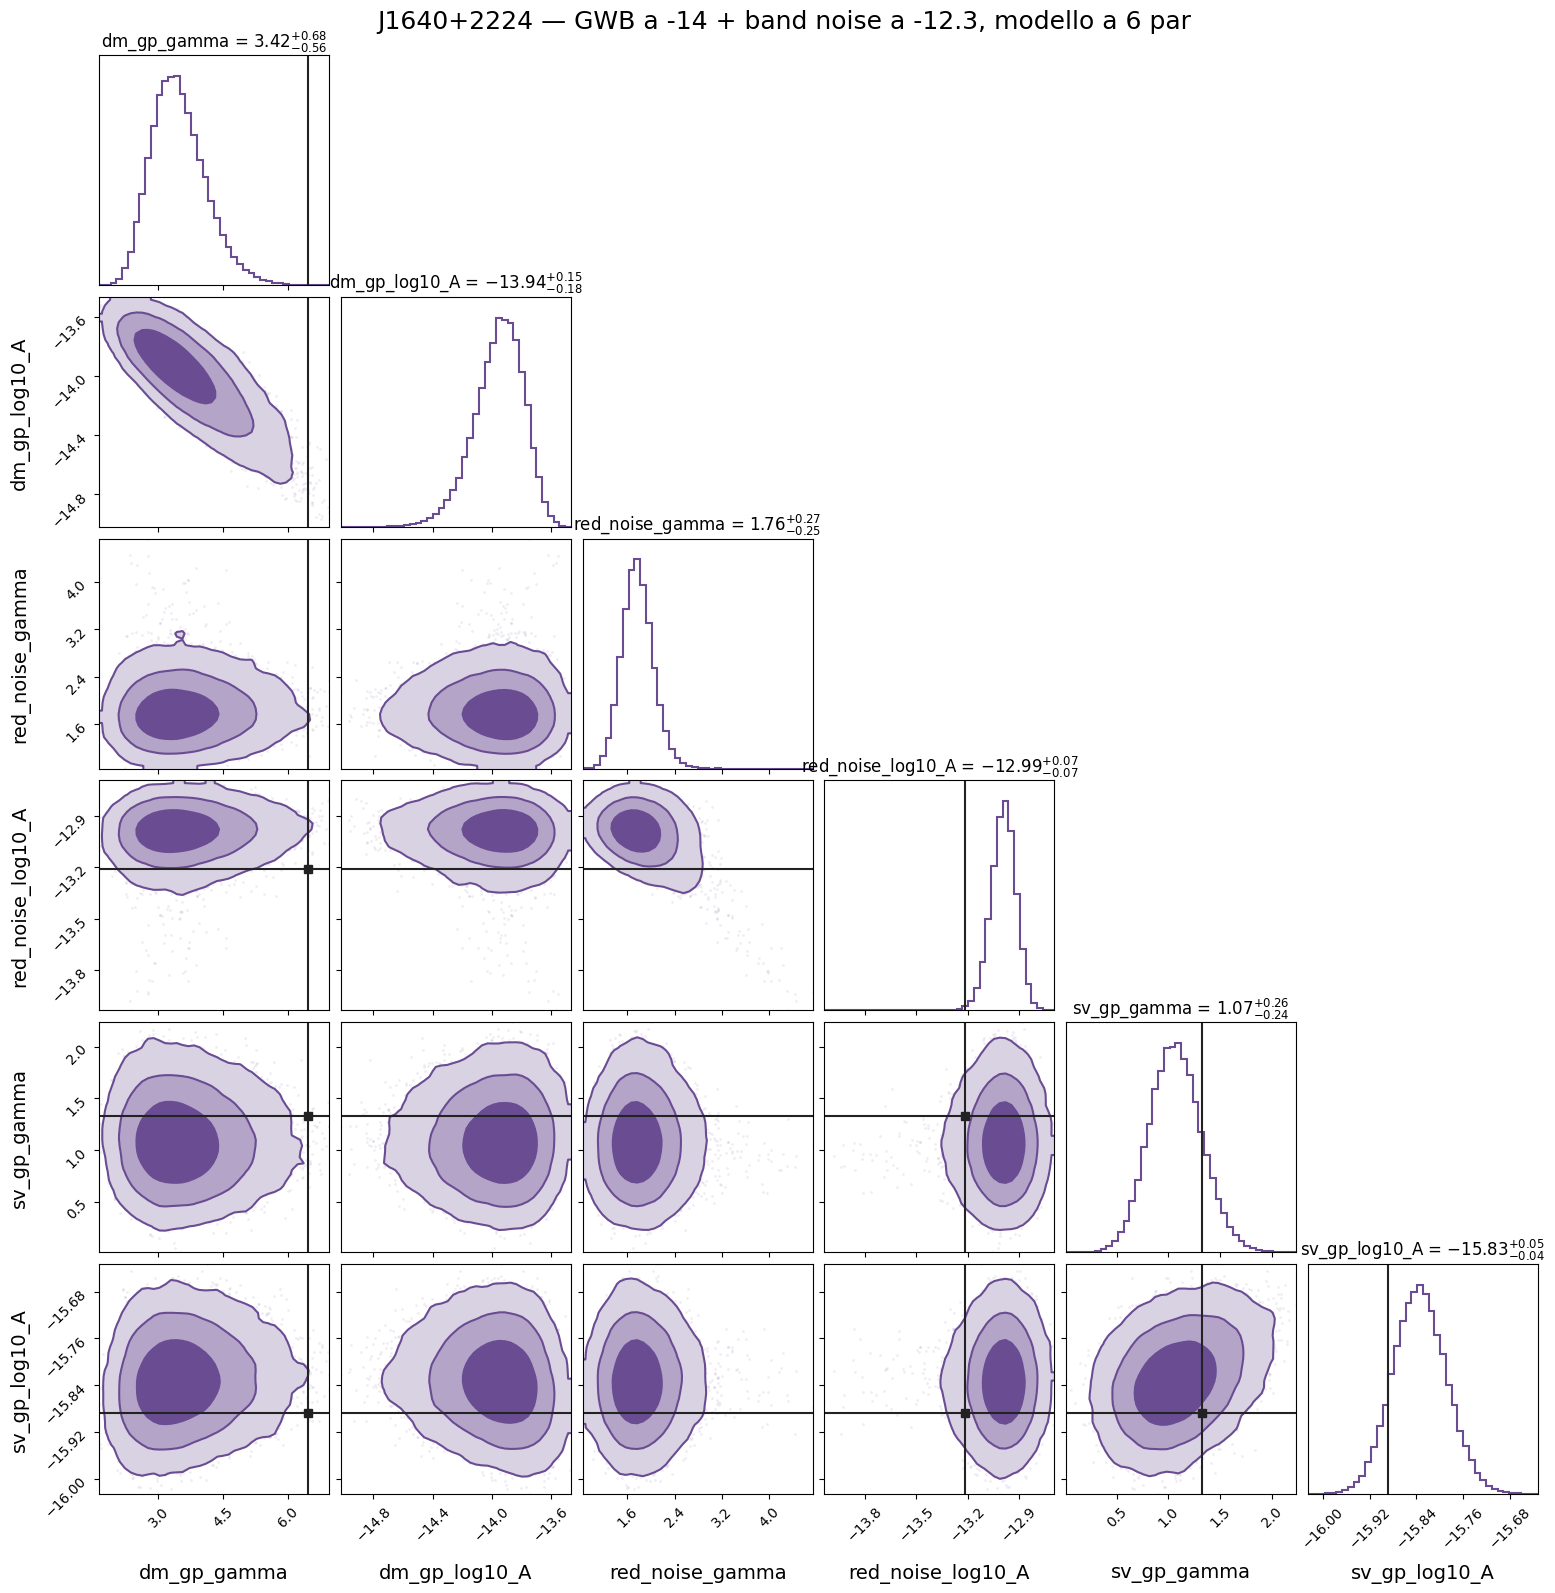

In [20]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

fig = corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#6A4C93',
    hist_kwargs={'color': '#6A4C93', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB a -14 + band noise a -12.3, modello a 6 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_6par.png', dpi=150, bbox_inches='tight')

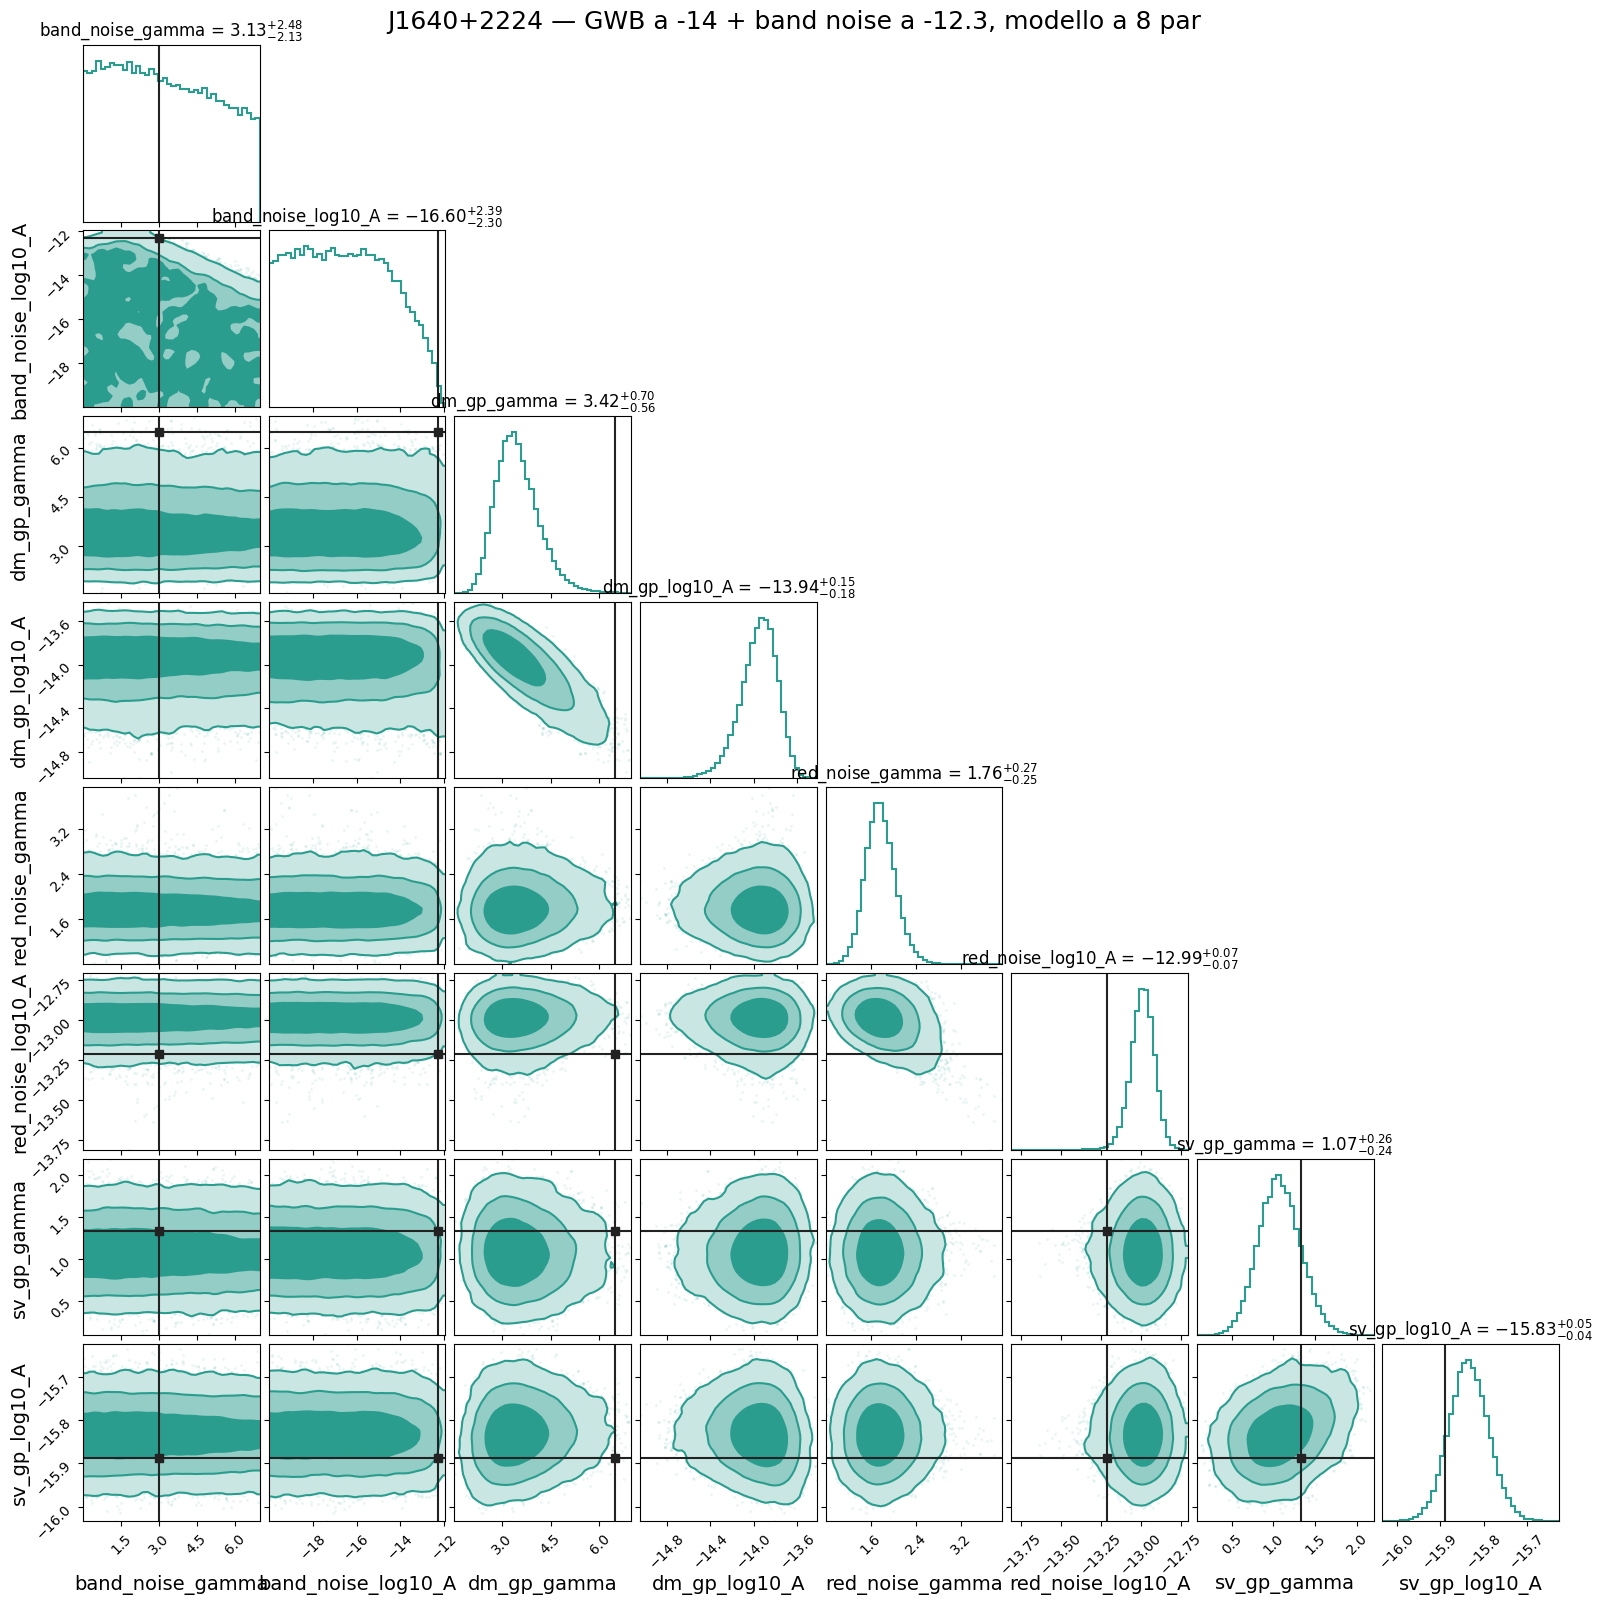

In [21]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -12.3,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_8par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_8par.params]

fig = corner.corner(
    chain_gwbbn_8par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB a -14 + band noise a -12.3, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_8par.png', dpi=150, bbox_inches='tight')

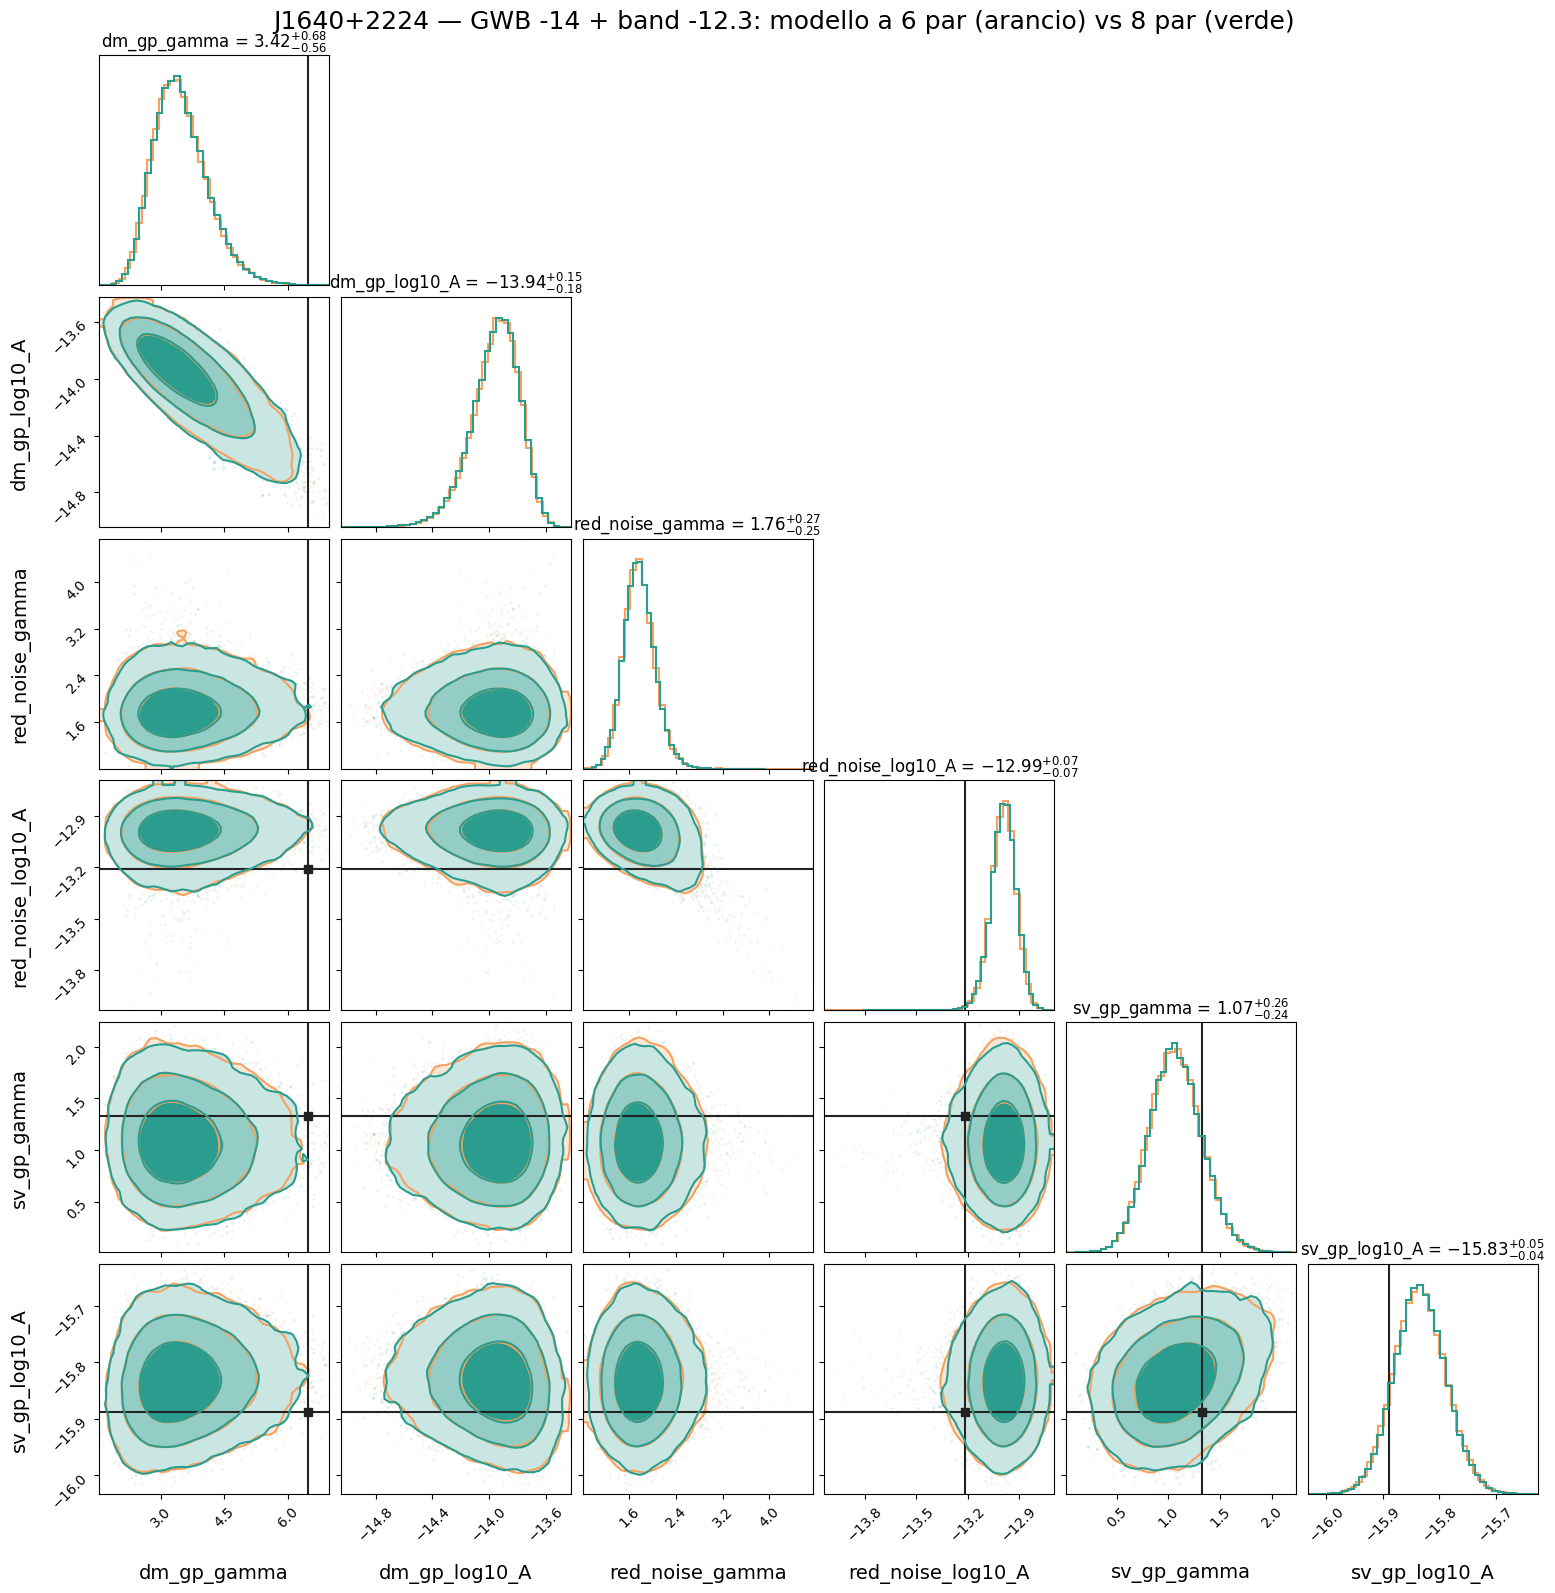

In [22]:
# dalla catena a 8 par tengo solo le 6 colonne comuni, nell ordine del modello a 6 par
chain_gwbbn_8par_comuni = chain_gwbbn_8par[:, [list(logL_gwbbn_8par.params).index(p) for p in logL_gwbbn_6par.params]]
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

# Primo corner
fig = corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB -14 + band -12.3: modello a 6 par (arancio) vs 8 par (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## Confronti con dati reali e altre simulazioni (modello a 6 par)

Le catene di confronto vengono lette da disco: nessun sampling. Hanno tutte i 6 parametri standard nello
stesso ordine di `logL_gwbbn_6par.params`.

In [24]:
# chain_gwb = np.loadtxt('./test_gwb_A140_g433_sv44/chain_1.txt')[:, :-4]
# chain_gwb = chain_gwb[len(chain_gwb)//4:]

chain_real = np.loadtxt('./test_real_sv44/chain_1.txt')[:, :-4]
chain_real = chain_real[len(chain_real)//4:]

chain_off = np.loadtxt('./test_sim_bn_OFF_50comp/chain_1.txt')[:, :-4]
chain_off = chain_off[len(chain_off)//4:]

chain_gwb = np.loadtxt('./test_gwb_A140_g433_sv44/chain_1.txt')[:, :-4]   # notebook 12: va lanciato prima
chain_gwb = chain_gwb[len(chain_gwb)//4:]

chain_bn125 = np.loadtxt('./test_sim_bn_A125_50comp/chain_1.txt')[:, :-4]
chain_bn125 = chain_bn125[len(chain_bn125)//4:]

print(chain_real.shape, chain_off.shape, chain_gwb.shape, chain_bn125.shape)

FileNotFoundError: ./test_gwb_A140_g433_sv44/chain_1.txt not found.

In [25]:
# mediana e intervallo al 68% di ogni parametro, per tutte le catene
catene = [('reali', chain_real), ('OFF', chain_off), ('solo GWB', chain_gwb),
          ('solo band -12.5', chain_bn125), ('GWB + band', chain_gwbbn_6par)]

for i, name in enumerate(logL_gwbbn_6par.params):
    riga = f"{name.replace('J1640+2224_', ''):20s}"
    for etichetta, ch in catene:
        q16, q50, q84 = np.percentile(ch[:, i], [16, 50, 84])
        riga += f"  {etichetta}: {q50:7.2f} [{q16:6.2f},{q84:6.2f}]"
    print(riga)

NameError: name 'chain_gwb' is not defined

### GWB + band vs dati reali

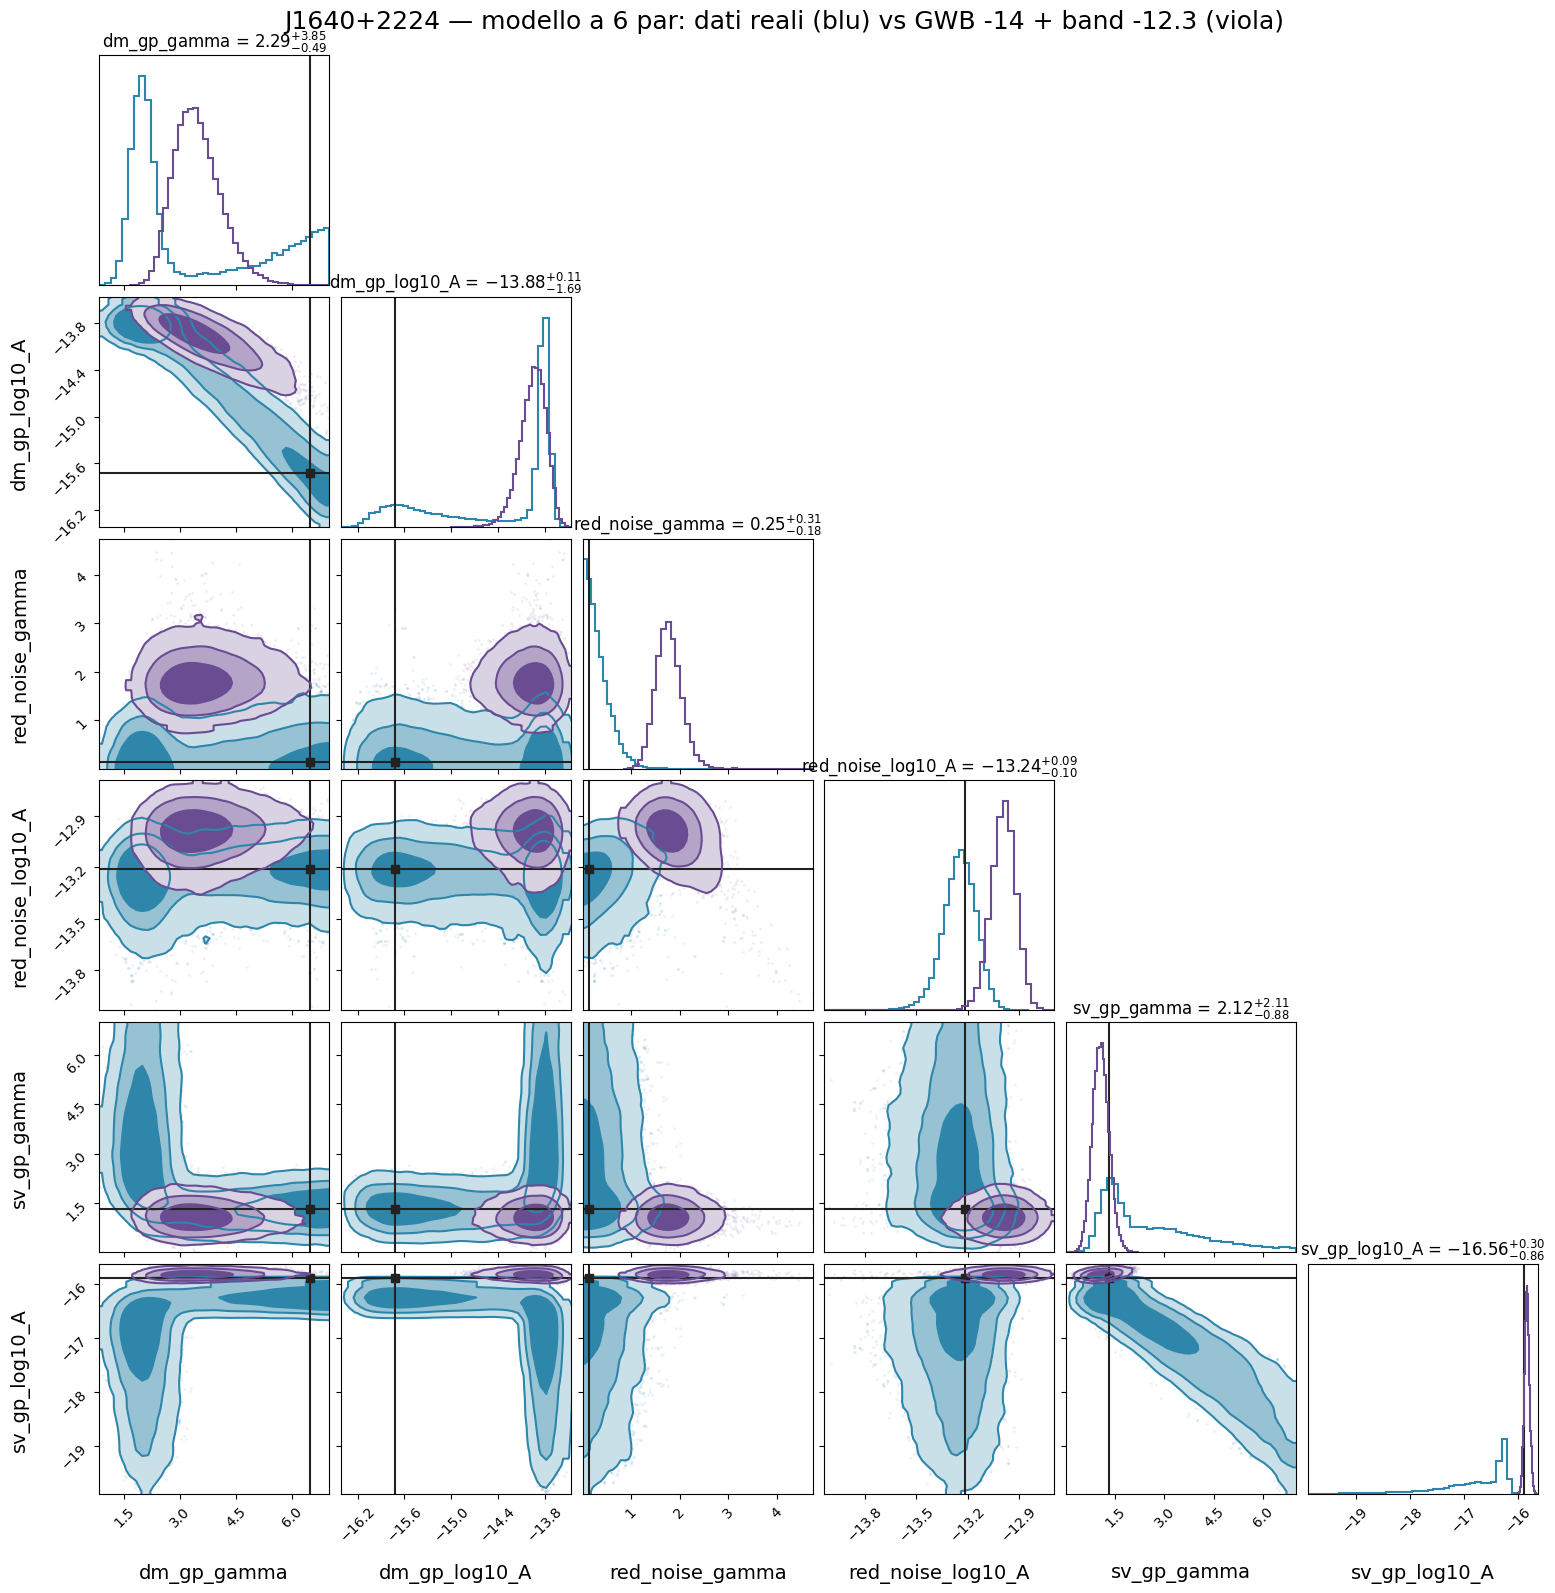

In [26]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

# Primo corner
fig = corner.corner(
    chain_real[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2E86AB',
    hist_kwargs={'color': '#2E86AB', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#6A4C93',
    hist_kwargs={'color': '#6A4C93', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: dati reali (blu) vs GWB -14 + band -12.3 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_vs_reali.png', dpi=150, bbox_inches='tight')

### GWB + band vs senza GWB e senza band

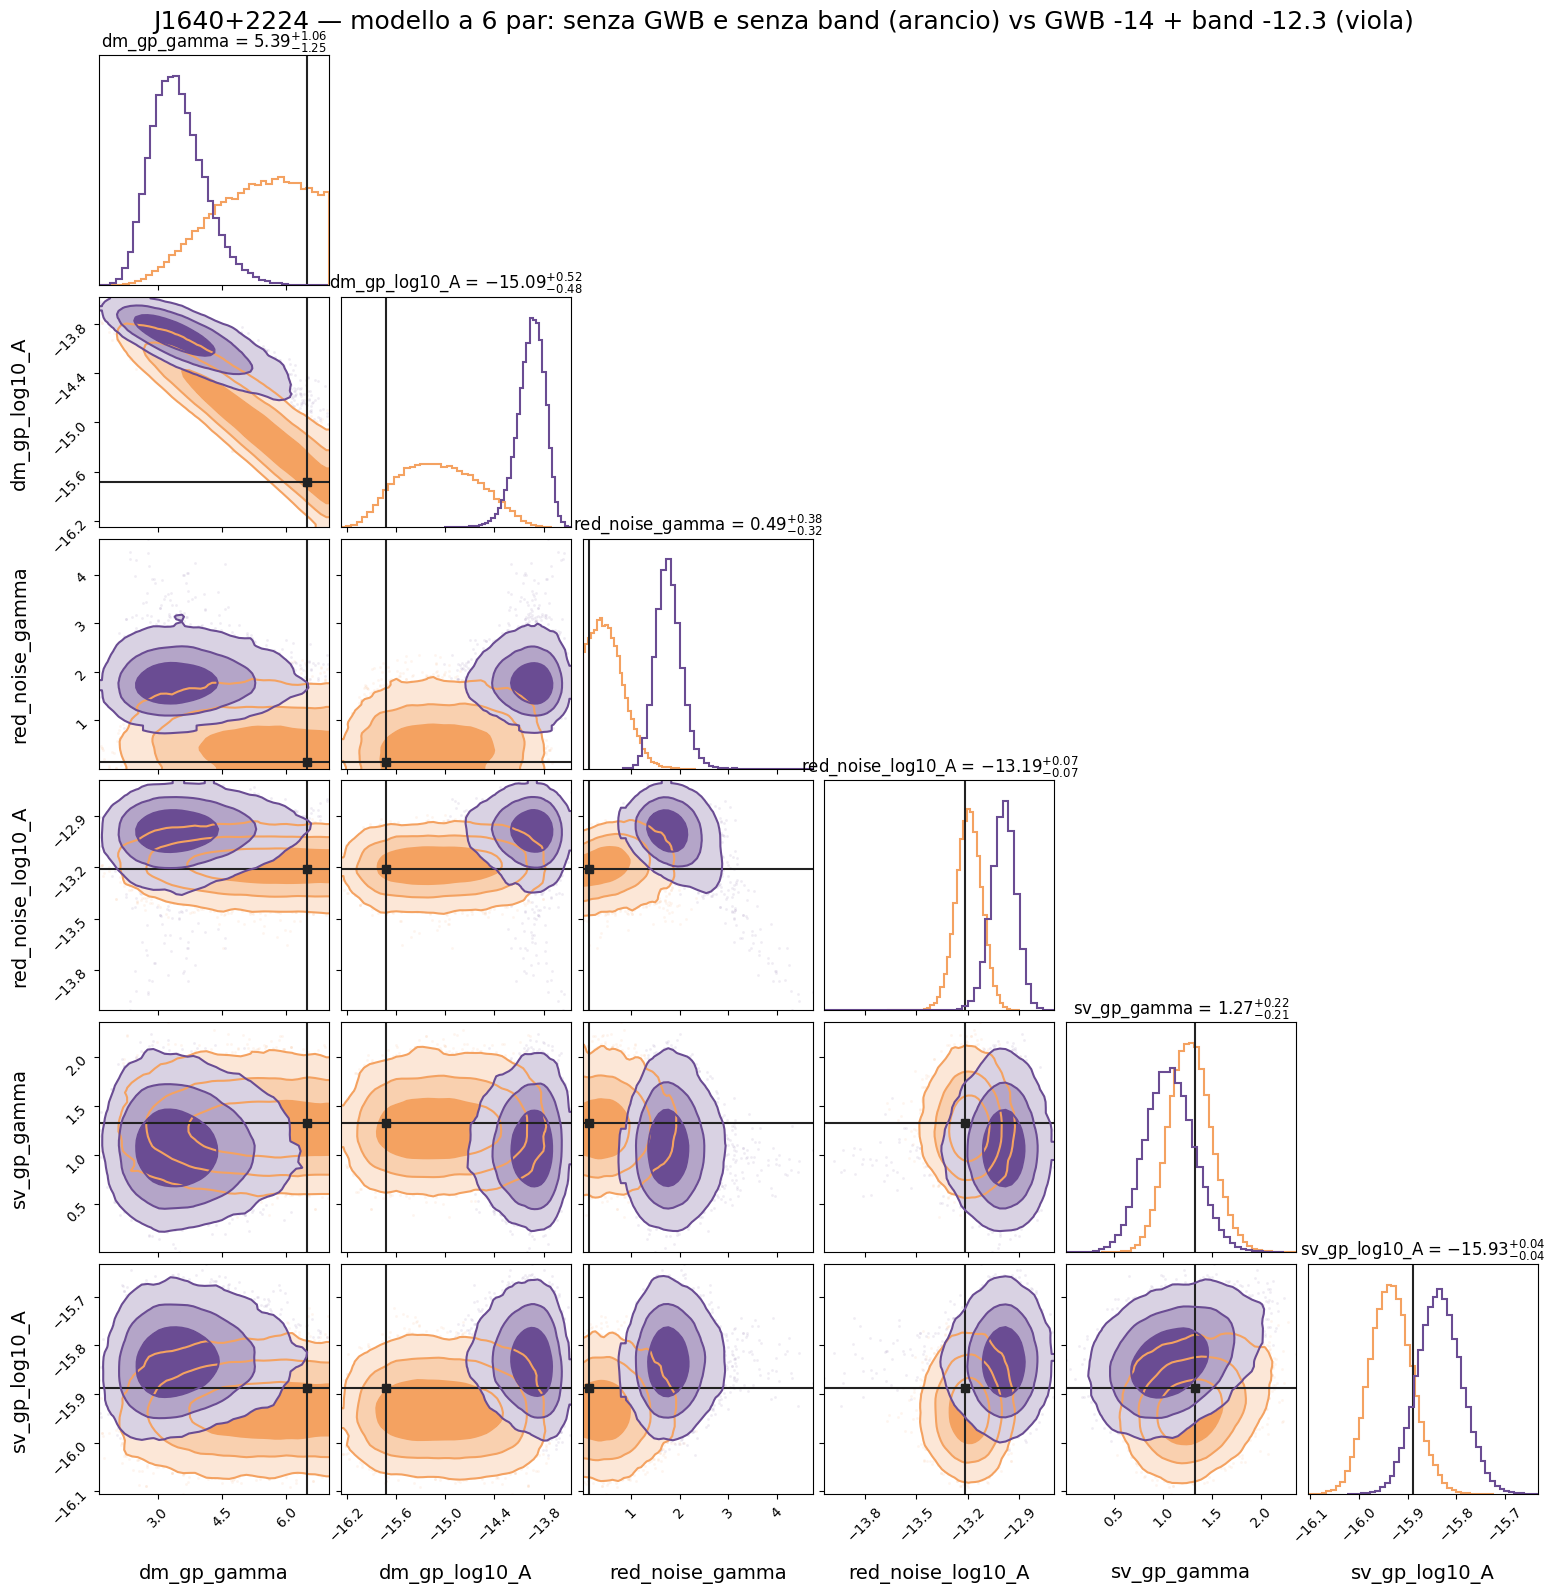

In [27]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

# Primo corner
fig = corner.corner(
    chain_off[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#6A4C93',
    hist_kwargs={'color': '#6A4C93', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: senza GWB e senza band (arancio) vs GWB -14 + band -12.3 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_vs_OFF.png', dpi=150, bbox_inches='tight')

### GWB + band vs solo GWB

In [ ]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

# Primo corner
fig = corner.corner(
    chain_gwb[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#457B9D',
    hist_kwargs={'color': '#457B9D', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#6A4C93',
    hist_kwargs={'color': '#6A4C93', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: solo GWB (azzurro) vs GWB -14 + band -12.3 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_vs_soloGWB.png', dpi=150, bbox_inches='tight')

### GWB + band vs solo band a -12.5

In [ ]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_6par.params]

# Primo corner
fig = corner.corner(
    chain_bn125[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#E76F51',
    hist_kwargs={'color': '#E76F51', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#6A4C93',
    hist_kwargs={'color': '#6A4C93', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: solo band a -12.5 (rosso) vs GWB -14 + band -12.3 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A123_GWB_vs_solobn125.png', dpi=150, bbox_inches='tight')

## Riepilogo

In [ ]:
# modello a 6 par: mediana e intervallo al 68% di ogni parametro per tutte le catene
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
etichette = ['reali', 'OFF', 'solo GWB', 'solo band', 'GWB+band']
catene = [chain_real, chain_off, chain_gwb, chain_bn125, chain_gwbbn_6par]
colori = ['#2E86AB', '#F4A261', '#457B9D', '#E76F51', '#6A4C93']

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (i, name) in zip(axs.flat, enumerate(logL_gwbbn_6par.params)):
    for j, (ch, col) in enumerate(zip(catene, colori)):
        q16, q50, q84 = np.percentile(ch[:, i], [16, 50, 84])
        ax.errorbar(j, q50, yerr=[[q50 - q16], [q84 - q50]], fmt='o', color=col, capsize=4)
    ax.axhline(truths_dict[name], color='#222222', lw=1)
    ax.set_xticks(range(len(etichette)))
    ax.set_xticklabels(etichette, rotation=30)
    ax.set_title(name.replace('J1640+2224_', ''), fontsize=12)
    ax.grid(alpha=0.25, linestyle='--')

fig.suptitle('Modello a 6 par: dati reali e simulazioni a confronto (linea nera = valori iniettati)', fontsize=15)
fig.tight_layout()
fig.savefig('riepilogo_GWB_bn_A123_confronti.png', dpi=150, bbox_inches='tight')

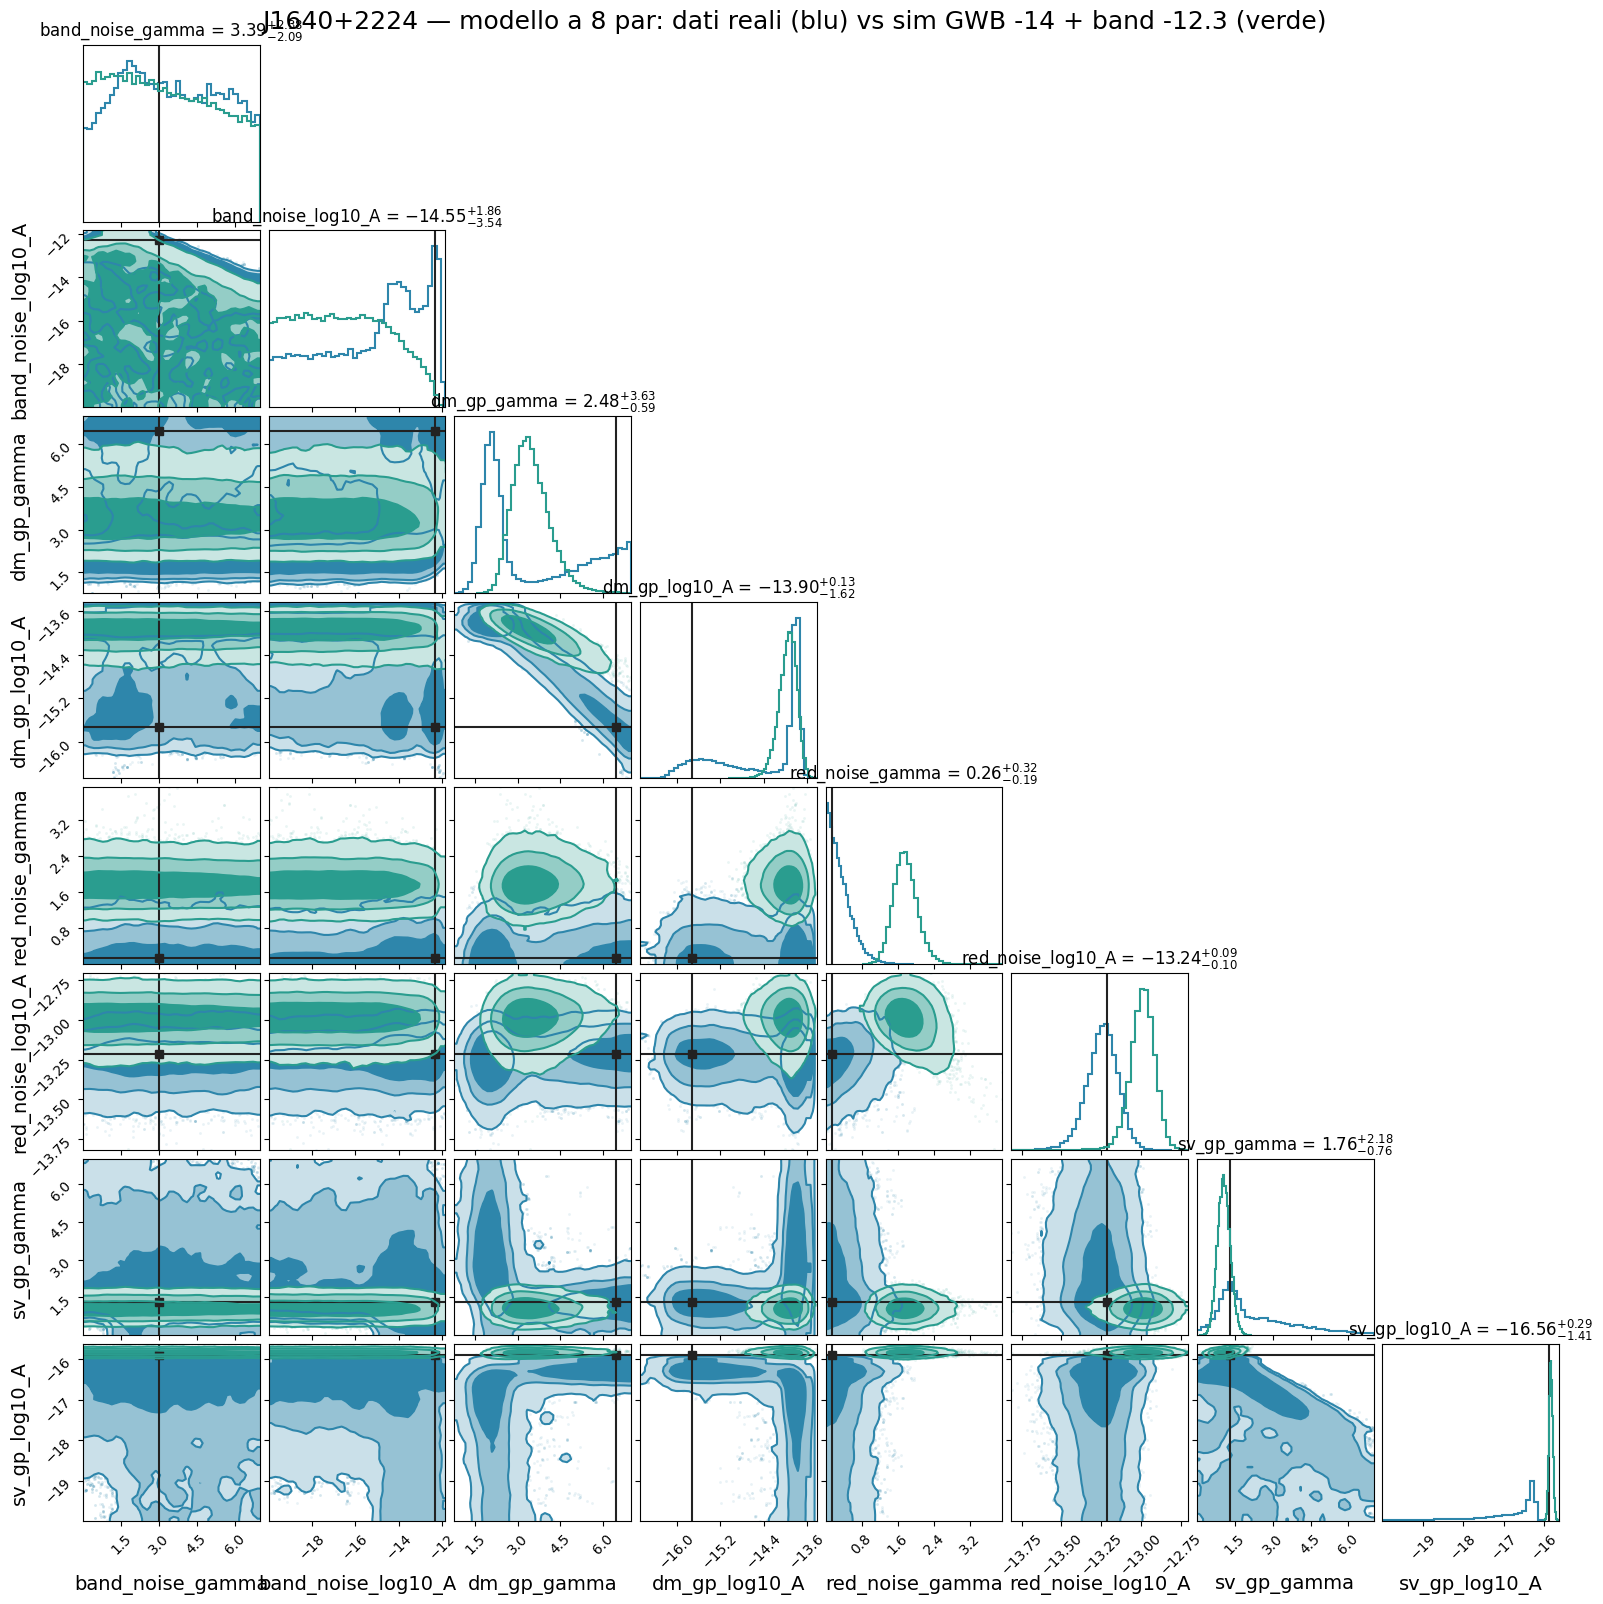

In [28]:
# dati reali analizzati con il modello a 8 par (notebook 20): stesso modello, stesso ordine dei parametri
chain_real_8par = np.loadtxt('./test_real_bn_bnmodel/chain_1.txt')[:, :-4]
chain_real_8par = chain_real_8par[len(chain_real_8par)//4:]
assert chain_real_8par.shape[1] == chain_gwbbn_8par.shape[1]

truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -12.3,
}
truth_values = [truths_dict[p] for p in logL_gwbbn_8par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_gwbbn_8par.params]

# Primo corner: dati reali in blu
fig = corner.corner(
    chain_real_8par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2E86AB',
    hist_kwargs={'color': '#2E86AB', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner: sim GWB + band in verde, sovrapposto
corner.corner(
    chain_gwbbn_8par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 8 par: dati reali (blu) vs sim GWB -14 + band -12.3 (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_reali_vs_sim_bn_A123_GWB_8par.png', dpi=150, bbox_inches='tight')